In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

# Project directory
ROOT = Path.cwd().resolve().parent

# Results and figures directories
RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"

FIGURES.mkdir(parents=True, exist_ok=True)

horizons = [1, 5, 20, 60]

COLORS = {
    "actual": "black",
    "mlp": "royalblue",
    "arimax": "darkorange"
}

plt.style.use("default")

test = pd.read_csv(
    ROOT / "data" / "test.csv",
    parse_dates=["Date"]
)

step = 10
max_h = 60

origins = np.arange(
    0,
    len(test) - max_h + 1,
    step
)

comparison_data = {}

for h in horizons:

    arimax = pd.read_csv(
        RESULTS / f"arimax_backtest_h{h}.csv",
        parse_dates=["Target_Date"]
    )

    mlp = pd.read_csv(
        RESULTS / f"mlp_backtest_h{h}.csv"
    )

    # Reconstruct MLP target dates if necessary
    if "Target_Date" not in mlp.columns:
        mlp["Target_Date"] = (
            test["Date"].iloc[origins + h - 1].to_numpy()
        )

    mlp["Target_Date"] = pd.to_datetime(
        mlp["Target_Date"]
    )

    # Match common target dates
    df = pd.merge(
        arimax[
            ["Target_Date", "Actual", "Predicted", "Origin_Price"]
        ],
        mlp[
            ["Target_Date", "Predicted", "Origin_Price"]
        ],
        on="Target_Date",
        how="inner",
        suffixes=("_ARIMAX", "_MLP")
    )

    df = df.sort_values("Target_Date").reset_index(drop=True)

    if df.empty:
        raise ValueError(
            f"No matching forecast dates for horizon {h}"
        )

    # Actual price change
    df["Actual_Change"] = (
        df["Actual"] - df["Origin_Price_ARIMAX"]
    )

    # Predicted price changes
    df["ARIMAX_Change"] = (
        df["Predicted_ARIMAX"]
        - df["Origin_Price_ARIMAX"]
    )

    df["MLP_Change"] = (
        df["Predicted_MLP"]
        - df["Origin_Price_MLP"]
    )

    # Forecast errors
    df["ARIMAX_Error"] = (
        df["Actual"] - df["Predicted_ARIMAX"]
    )

    df["MLP_Error"] = (
        df["Actual"] - df["Predicted_MLP"]
    )

    comparison_data[h] = df

    print(f"{h}-day: {len(df)} matched observations")


1-day: 137 matched observations
5-day: 137 matched observations
20-day: 137 matched observations
60-day: 137 matched observations


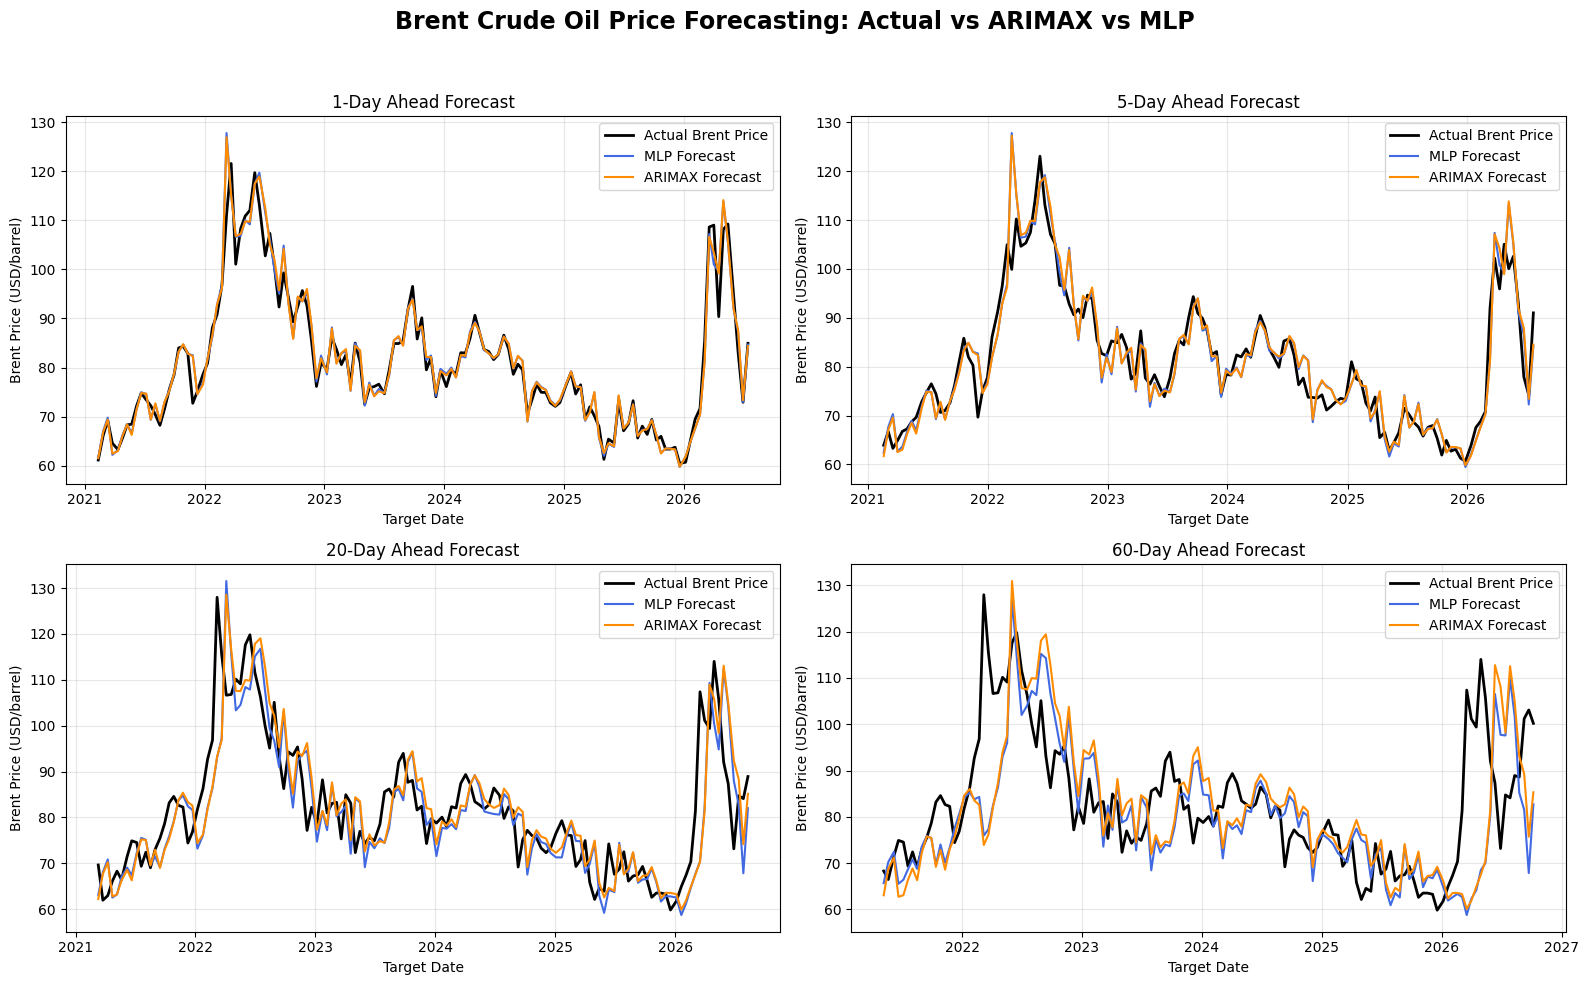

In [2]:
# FIGURE 1: ACTUAL VS FORECAST PRICE

fig, axes = plt.subplots(
    2, 2, figsize=(16, 10)
)

for ax, h in zip(axes.flat, horizons):

    df = comparison_data[h]

    ax.plot(
        df["Target_Date"],
        df["Actual"],
        color=COLORS["actual"],
        linewidth=2,
        label="Actual Brent Price"
    )

    ax.plot(
        df["Target_Date"],
        df["Predicted_MLP"],
        color=COLORS["mlp"],
        linewidth=1.5,
        label="MLP Forecast"
    )

    ax.plot(
        df["Target_Date"],
        df["Predicted_ARIMAX"],
        color=COLORS["arimax"],
        linewidth=1.5,
        label="ARIMAX Forecast"
    )

    ax.set_title(f"{h}-Day Ahead Forecast")
    ax.set_xlabel("Target Date")
    ax.set_ylabel("Brent Price (USD/barrel)")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.legend()
    ax.grid(alpha=0.3)

fig.suptitle(
    "Brent Crude Oil Price Forecasting: Actual vs ARIMAX vs MLP",
    fontsize=17,
    fontweight="bold"
)

fig.tight_layout(rect=[0, 0, 1, 0.95])

fig.savefig(
    FIGURES / "historical_price_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

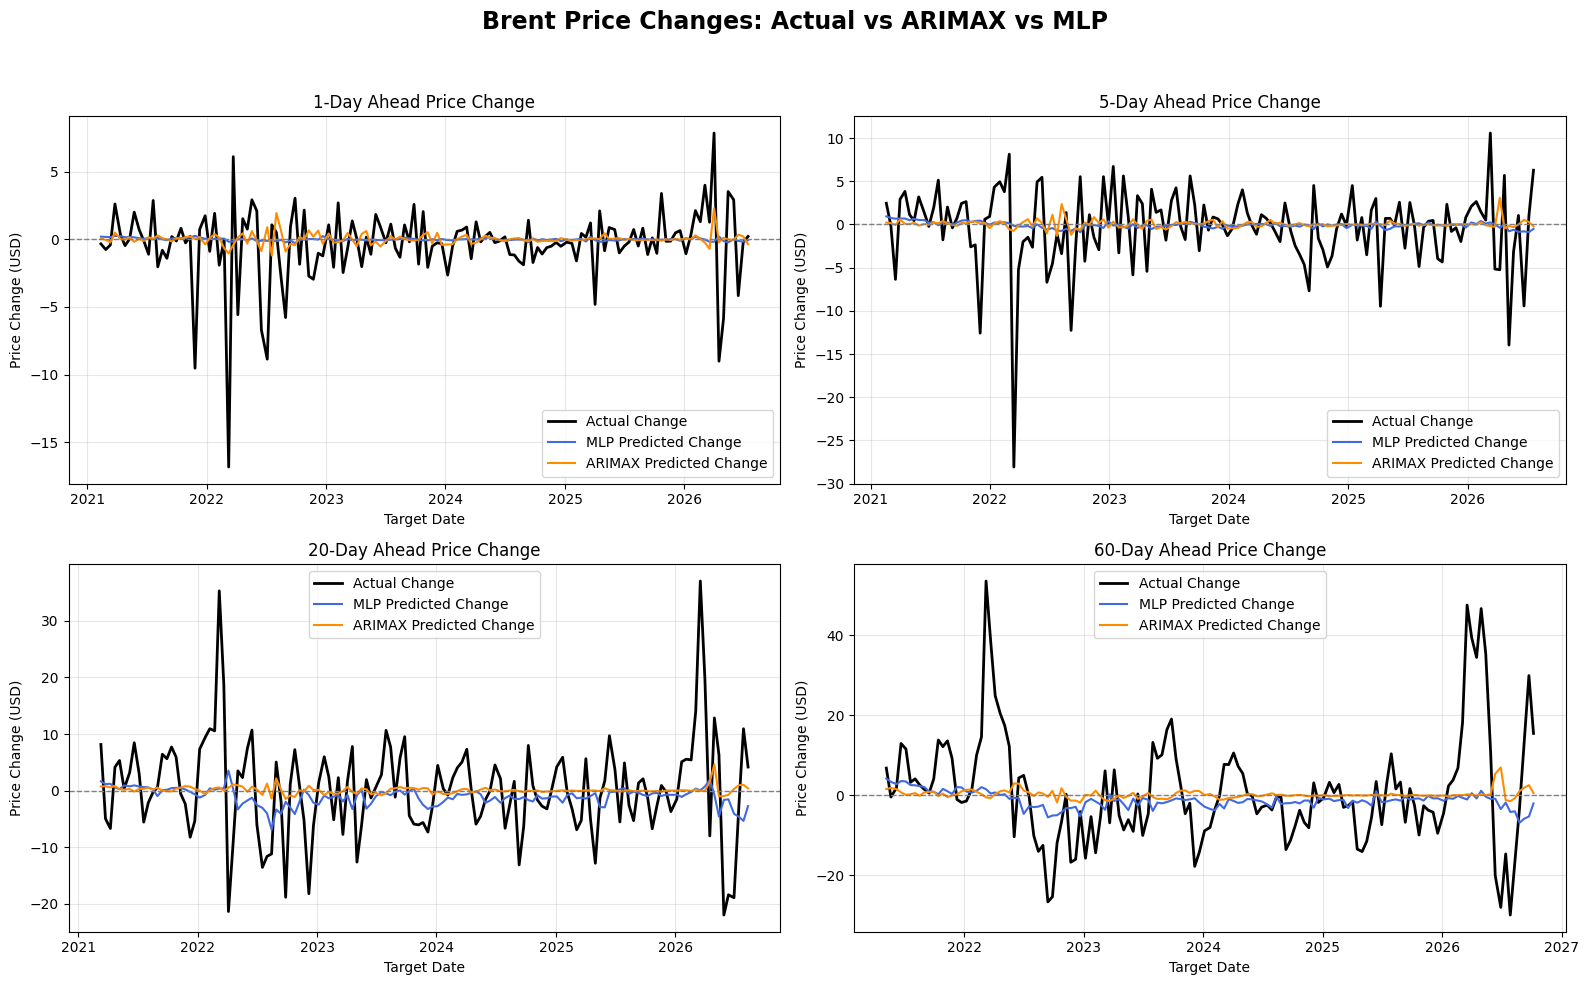

In [4]:
# FIGURE 2: PRICE CHANGE COMPARISON

fig, axes = plt.subplots(
    2, 2, figsize=(16, 10)
)

for ax, h in zip(axes.flat, horizons):

    df = comparison_data[h]

    ax.plot(
        df["Target_Date"],
        df["Actual_Change"],
        color=COLORS["actual"],
        linewidth=2,
        label="Actual Change"
    )

    ax.plot(
        df["Target_Date"],
        df["MLP_Change"],
        color=COLORS["mlp"],
        linewidth=1.5,
        label="MLP Predicted Change"
    )

    ax.plot(
        df["Target_Date"],
        df["ARIMAX_Change"],
        color=COLORS["arimax"],
        linewidth=1.5,
        label="ARIMAX Predicted Change"
    )

    ax.axhline(
        0,
        color="gray",
        linestyle="--",
        linewidth=1
    )

    ax.set_title(f"{h}-Day Ahead Price Change")
    ax.set_xlabel("Target Date")
    ax.set_ylabel("Price Change (USD)")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.legend()
    ax.grid(alpha=0.3)

fig.suptitle(
    "Brent Price Changes: Actual vs ARIMAX vs MLP",
    fontsize=17,
    fontweight="bold"
)

fig.tight_layout(rect=[0, 0, 1, 0.95])

fig.savefig(
    FIGURES / "historical_price_change_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


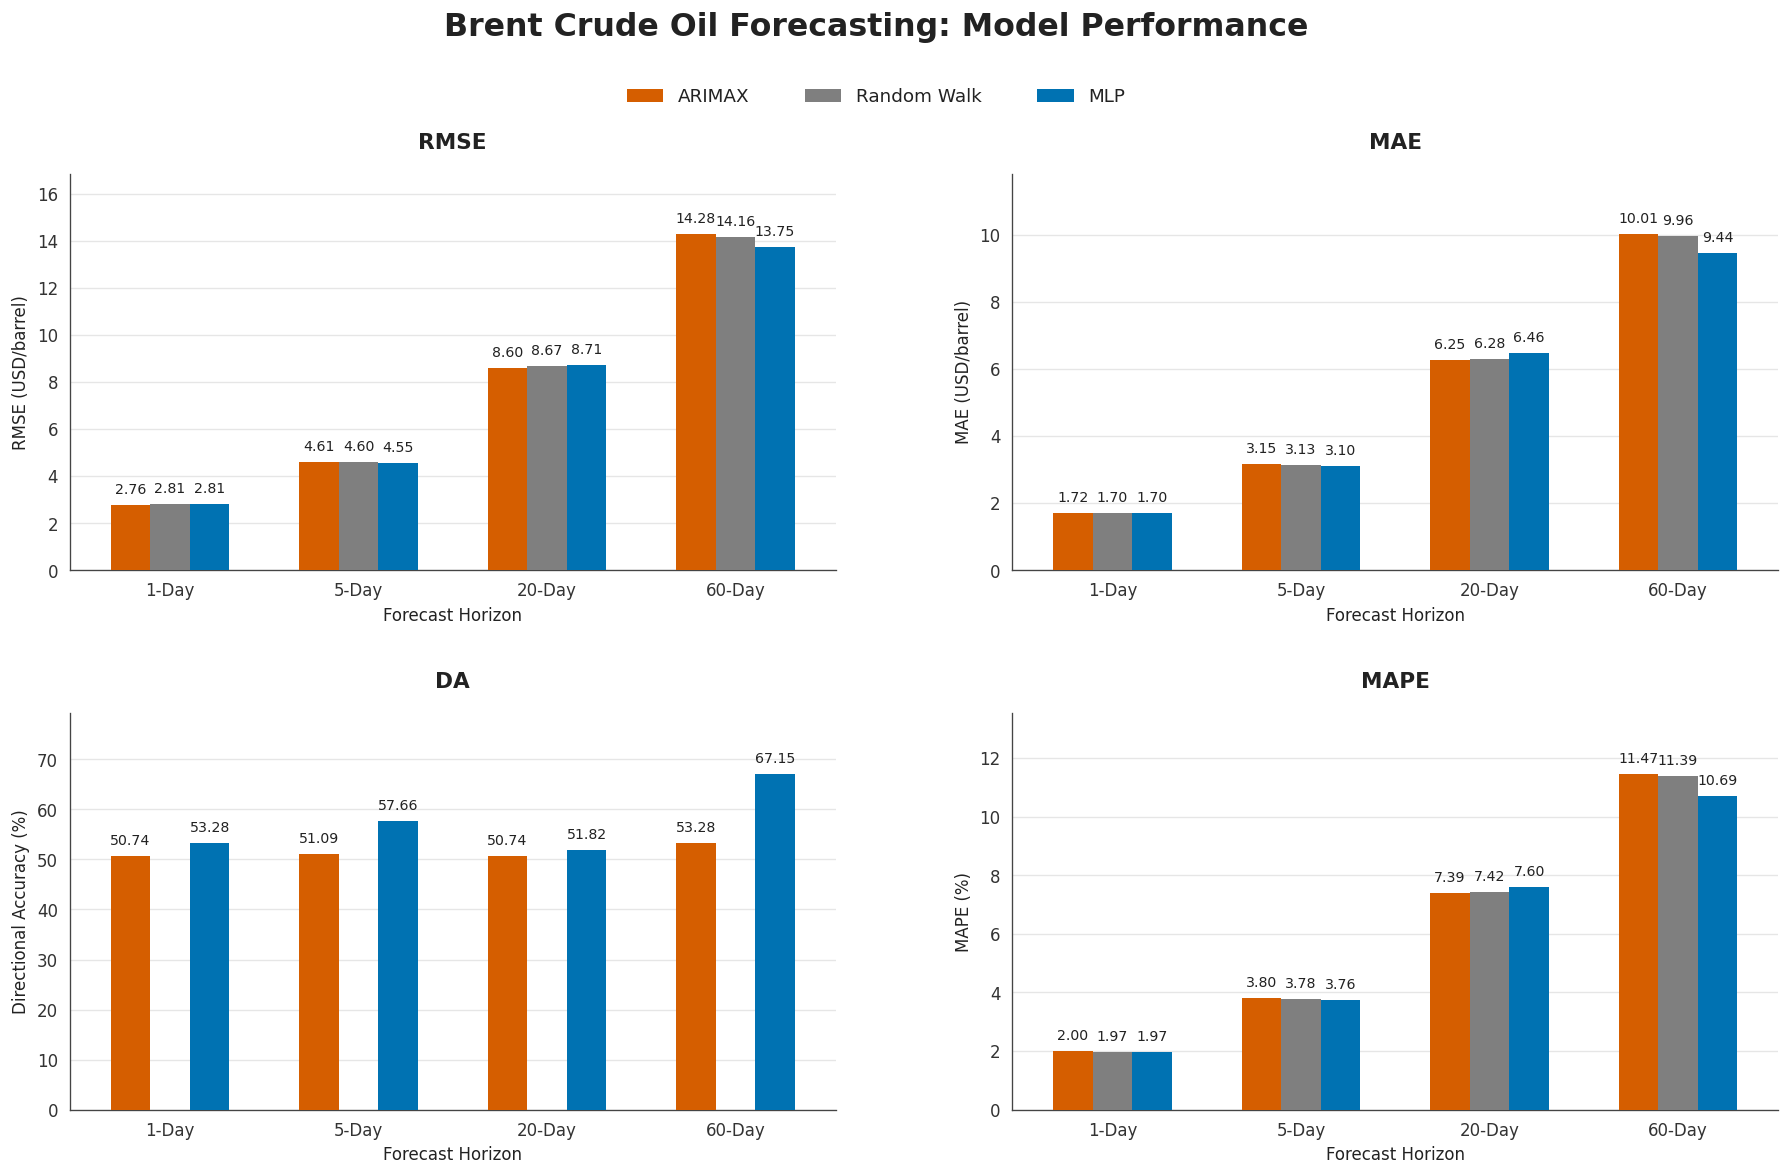

Figure saved to: C:\Users\qkq\Desktop\oil_price_forecast\figures\model_performance_comparison.png


In [10]:
# FIGURE 3: MODEL PERFORMANCE COMPARISON

# ==========================================
# 1. PATHS
# ==========================================

ROOT = Path(r"C:\Users\qkq\Desktop\oil_price_forecast")

RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"

FIGURES.mkdir(parents=True, exist_ok=True)

# ==========================================
# 2. LOAD DATA
# ==========================================

models = {
    "ARIMAX": pd.read_csv(
        RESULTS / "arimax_performance.csv"
    ),
    "Random Walk": pd.read_csv(
        RESULTS / "random_walk_performance.csv"
    ),
    "MLP": pd.read_csv(
        RESULTS / "mlp_performance.csv"
    )
}

horizons = [1, 5, 20, 60]
metrics = ["RMSE", "MAE", "DA", "MAPE"]

colors = {
    "ARIMAX": "#D55E00",
    "Random Walk": "#7F7F7F",
    "MLP": "#0072B2"
}

# ==========================================
# 3. PUBLICATION STYLE
# ==========================================

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#444444",
    "axes.labelcolor": "#222222",
    "text.color": "#222222",
    "xtick.color": "#333333",
    "ytick.color": "#333333",
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "savefig.facecolor": "white"
})

# ==========================================
# 4. CREATE FIGURE
# ==========================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(16, 10),
    dpi=120
)

x = np.arange(len(horizons))

# Narrower bars and visible gaps
width = 0.21
offsets = [-width, 0, width]

model_names = list(models.keys())

for ax, metric in zip(axes.flat, metrics):

    all_values = []

    for i, model_name in enumerate(model_names):

        df = models[model_name]

        values = (
            df.set_index("Horizon")
              .loc[horizons, metric]
              .to_numpy(dtype=float)
        )

        all_values.extend(values)

        bars = ax.bar(
            x + offsets[i],
            values,
            width=width,
            color=colors[model_name],
            edgecolor="white",
            linewidth=0,
            label=model_name,
            zorder=3
        )

        # Numerical labels
        for bar, value in zip(bars, values):

            if not np.isfinite(value):
                continue

            ax.annotate(
                f"{value:.2f}",
                xy=(
                    bar.get_x() + bar.get_width() / 2,
                    bar.get_height()
                ),
                xytext=(0, 5),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=8.5,
                fontweight="medium",
                color="#222222"
            )

    # Titles
    ax.set_title(
        metric,
        pad=15
    )

    ax.set_xticks(x)
    ax.set_xticklabels(
        [f"{h}-Day" for h in horizons]
    )

    ax.set_xlabel("Forecast Horizon")

    if metric == "DA":
        ax.set_ylabel("Directional Accuracy (%)")

    elif metric == "MAPE":
        ax.set_ylabel("MAPE (%)")

    else:
        ax.set_ylabel(f"{metric} (USD/barrel)")

    # Subtle horizontal grid
    ax.grid(
        axis="y",
        color="#E6E6E6",
        linewidth=0.8,
        zorder=0
    )

    ax.tick_params(
        axis="both",
        length=0,
        pad=7
    )

    # Room for labels
    max_value = np.nanmax(all_values)

    ax.set_ylim(
        0,
        max_value * 1.18
    )

    ax.margins(x=0.06)

# ==========================================
# 5. SHARED LEGEND
# ==========================================

handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.945),
    ncol=3,
    frameon=False,
    fontsize=11,
    columnspacing=3
)

# ==========================================
# 6. FINAL LAYOUT
# ==========================================

fig.suptitle(
    "Brent Crude Oil Forecasting: Model Performance",
    fontsize=19,
    fontweight="bold",
    y=0.995
)

fig.subplots_adjust(
    top=0.86,
    bottom=0.08,
    left=0.08,
    right=0.97,
    hspace=0.36,
    wspace=0.23
)

# ==========================================
# 7. SAVE PNG ONLY
# ==========================================

output_path = FIGURES / "model_performance_comparison.png"

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:", output_path)